
# Week 2 In-Class Hands-On — Track D: Stellar Astrophysics
## Rediscovering the Hertzsprung-Russell Diagram Without Labels

**Course:** Machine Learning in Astronomy — Week 2 In-Class Session
**Data:** the real HYG v4.1 database (Hipparcos + Yale Bright Star + Gliese catalogs combined), 119,626 real stars with real apparent and absolute magnitudes, real B-V color index, real spectral classification, distance, and proper motion — loaded directly from its maintainers' own repository, `astronexus/HYG-Database` on GitHub.

## The problem

The Hertzsprung-Russell (HR) diagram — luminosity (or absolute magnitude) plotted against color (or temperature) — is arguably *the* foundational plot in stellar astrophysics. It reveals that stars are not scattered randomly: most sit on a **main sequence**, others form a **giant branch**, and a rare few are **white dwarfs** — physically distinct evolutionary stages. Every astronomy student has seen this diagram already labeled. Today we do something different: **pretend we don't know that structure exists**, and ask whether unsupervised learning — using only color and absolute magnitude, no spectral classification at all — rediscovers it on its own.

## Real data, real mess — handled honestly before any modeling

Two genuine data-quality issues, both found by actually inspecting the file rather than assumed:

- **A sentinel distance value.** 10,225 stars (8.5% of the catalog) have `dist = 100000` parsecs exactly — the HYG catalog's placeholder for "no measured parallax is available," not a real distance. Any absolute magnitude computed from that placeholder is meaningless and must be dropped, not just noted.
- **Missing and ambiguous spectral types.** The `spect` column is blank for 3,048 stars, and for many others it's genuinely ambiguous — compound entries like `"F3/F5IV"` or `"G0V + K:III:"` (an uncertain classification, or literally a blended binary spectrum). We will use spectral type **only as an after-the-fact peek**, and only for the subset where it parses cleanly into a single, unambiguous luminosity class — a real, honest limitation on how much of the catalog that peek can even speak to, which we state as a number, not swept under the rug.

Every method below is applied at least three different ways where it matters, so you see real methods disagree with each other, not just watch one pipeline run end to end.


In [1]:

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.semi_supervised import LabelSpreading
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, adjusted_rand_score,
    accuracy_score, roc_auc_score
)

np.random.seed(42)
%matplotlib inline
plt.rcParams['figure.dpi'] = 100
print("Environment ready.")


Environment ready.



## Step 1: Load the real data and clean it honestly


In [2]:

url = "https://raw.githubusercontent.com/astronexus/HYG-Database/main/hyg/CURRENT/hygdata_v41.csv"
hyg = pd.read_csv(url)
print(f"Rows before cleaning: {len(hyg)}")

hyg = hyg[hyg['dist'] < 100000].copy()          # drop the "no parallax measured" sentinel
hyg = hyg[hyg['ci'].notna()].copy()             # drop missing color index
hyg['pm_total'] = np.sqrt(hyg['pmra']**2 + hyg['pmdec']**2)
hyg['log_dist'] = np.log10(hyg['dist'].clip(lower=0.1))
print(f"Rows after cleaning: {len(hyg)}")


Rows before cleaning: 119626
Rows after cleaning: 107860



### Parsing a real, messy `spect` string into an honest peek label

We deliberately use a simple, transparent rule rather than a full spectral-classification parser: white dwarfs are flagged by a leading `D`; otherwise we search for a Roman-numeral luminosity class (V = dwarf/main-sequence, IV = subgiant, III/II = giant, I = supergiant). Any entry containing `/` or `+` (a compound or blended classification) is left **unparsed** — excluded from the peek entirely, not guessed at.


In [3]:

def peek_class(spect):
    if pd.isna(spect):
        return None
    if '/' in spect or '+' in spect:
        return None
    if spect.startswith('D'):
        return 'white_dwarf'
    m = re.search(r'(VII|VI|IV|III|II|Ib|Ia|I|V)', spect)
    if not m:
        return None
    token = m.group(1)
    if token == 'V':
        return 'dwarf'
    if token == 'IV':
        return 'subgiant'
    if token in ('III', 'II'):
        return 'giant'
    return 'supergiant'

hyg['peek'] = hyg['spect'].apply(peek_class)
print("Peek label coverage (the rest is genuinely unparseable or ambiguous, and stays that way):")
print(hyg['peek'].value_counts(dropna=False))
print(f"\nCoverage: {hyg['peek'].notna().mean():.1%} of the cleaned catalog got an unambiguous peek label.")


Peek label coverage (the rest is genuinely unparseable or ambiguous, and stays that way):
peek
NaN            66147
dwarf          20649
giant          16761
subgiant        3706
supergiant       448
white_dwarf      149
Name: count, dtype: int64

Coverage: 38.7% of the cleaned catalog got an unambiguous peek label.



### Look at the real data before clustering anything

The classic 2D HR diagram, plus a third axis — distance — to see something the 2D version hides: are nearby and far-away stars sampling the same populations, or different ones?


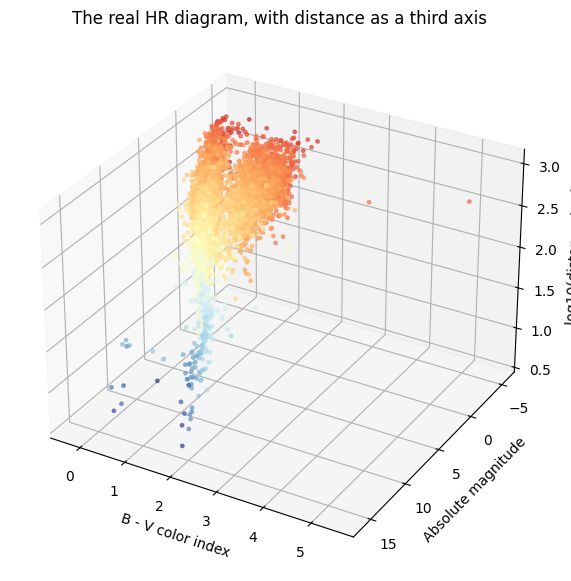

In [4]:

rng = np.random.default_rng(0)
sample = hyg.iloc[rng.choice(len(hyg), size=6000, replace=False)].reset_index(drop=True)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(sample['ci'], sample['absmag'], sample['log_dist'], c=sample['absmag'],
                 cmap='RdYlBu', s=6, alpha=0.6)
ax.set_xlabel('B - V color index'); ax.set_ylabel('Absolute magnitude'); ax.set_zlabel('log10(distance / pc)')
ax.invert_yaxis()  # brighter (more negative) absolute magnitude conventionally plotted upward
ax.set_title('The real HR diagram, with distance as a third axis')
plt.show()



Rotate this plot. The main sequence should read as a long diagonal band (blue, bright, hot stars to red, faint, cool stars); a separate, less populated branch of red-but-bright giants should sit apart from it. Notice whether the *distance* axis shows any structure too — real magnitude-limited catalogs like this one only detect intrinsically bright stars (giants) out to very large distances, while intrinsically faint stars (most dwarfs) only make the catalog if they happen to be nearby. Keep this in mind; it resurfaces as a real, physical explanation in Step 5.

**🔧 Try it yourself:** color the same plot by `sample['peek']` instead of absolute magnitude (you'll need to convert the categories to numeric codes first) — do the giant, dwarf, and white-dwarf labels occupy visually distinct regions of this 3D space?


In [5]:

X = StandardScaler().fit_transform(sample[['ci', 'absmag']].values)
peek = sample['peek'].values
peek_notna = pd.notna(peek)
wd_mask = (peek == 'white_dwarf')
print(f"White dwarfs in this sample: {wd_mask.sum()} (out of {len(sample)})")


White dwarfs in this sample: 7 (out of 6000)



## Step 2: A baseline for unsupervised work

Same discipline as every other track: a random partition into the same number of groups first.


In [6]:

random_labels = rng.integers(0, 3, size=len(X))
baseline_silhouette = silhouette_score(X, random_labels)
baseline_db = davies_bouldin_score(X, random_labels)
print(f"Random-partition baseline - silhouette: {baseline_silhouette:.3f}, Davies-Bouldin: {baseline_db:.3f}")


Random-partition baseline - silhouette: -0.005, Davies-Bouldin: 107.013



## Step 3: Three clustering methods, compared honestly

- **K-means**: hard-assigns every star to the nearest of $k$ centers.
- **Gaussian Mixture Model**: soft-assigns a probability of membership to each of $k$ Gaussian components.
- **DBSCAN**: a genuinely different mechanism from the other two, and the one real published open-cluster membership papers actually use (e.g. arXiv:[2404.10477](https://arxiv.org/abs/2404.10477), "Membership determination in open clusters using the DBSCAN Clustering Algorithm," 2024) — it doesn't fix the number of clusters in advance, and critically, it doesn't force every point into a cluster: sufficiently isolated points are simply labeled **noise**.

DBSCAN needs a neighborhood radius (`eps`), and results are genuinely sensitive to it — worth seeing directly rather than taking on faith. We'll use a k-distance plot (a standard way to pick `eps`: sort every point's distance to its 10th-nearest neighbor, and look for where that distance starts climbing steeply) and then a small sensitivity sweep.


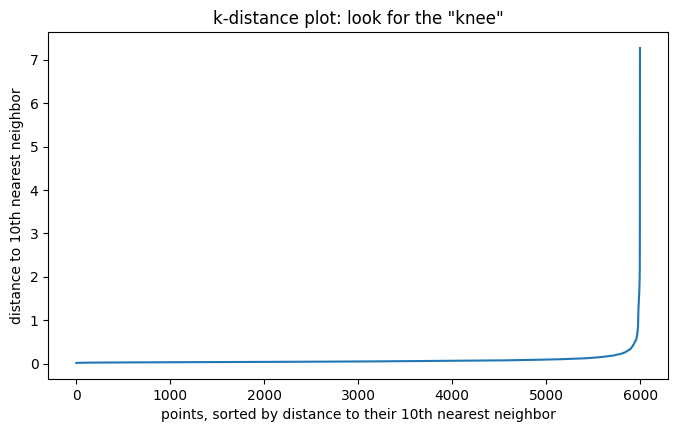

   eps  n_clusters   n_noise   noise %
  0.05          30      2308     38.5%
  0.08           9       925     15.4%
  0.10           5       584      9.7%
  0.15           2       261      4.3%


  0.20           2       146      2.4%
  0.30           1        74      1.2%


In [7]:

nbrs = NearestNeighbors(n_neighbors=10).fit(X)
dist_to_10th, _ = nbrs.kneighbors(X)
kdist_sorted = np.sort(dist_to_10th[:, -1])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(kdist_sorted)
ax.set_xlabel('points, sorted by distance to their 10th nearest neighbor')
ax.set_ylabel('distance to 10th nearest neighbor')
ax.set_title('k-distance plot: look for the "knee"')
plt.show()

print(f"{'eps':>6s}  {'n_clusters':>10s}  {'n_noise':>8s}  {'noise %':>8s}")
for eps in [0.05, 0.08, 0.10, 0.15, 0.20, 0.30]:
    db_labels = DBSCAN(eps=eps, min_samples=10).fit_predict(X)
    n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
    n_noise = int((db_labels == -1).sum())
    print(f"{eps:6.2f}  {n_clusters:10d}  {n_noise:8d}  {n_noise/len(db_labels):8.1%}")



**🔧 Try it yourself:** find where the k-distance curve's slope visibly steepens — a common rule of thumb is to set `eps` near that bend. Does it land close to the `eps=0.10` we use below, or somewhere else?


In [8]:

cluster_results = {}
cluster_results['K-means'] = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)
cluster_results['GMM'] = GaussianMixture(n_components=3, n_init=3, random_state=42).fit_predict(X)
cluster_results['DBSCAN'] = DBSCAN(eps=0.10, min_samples=10).fit_predict(X)

print(f"{'Method':10s}  {'Silhouette':>10s}  {'Davies-Bouldin':>15s}  {'ARI vs peek':>12s}  {'cluster sizes':>20s}")
print(f"{'Random':10s}  {baseline_silhouette:10.3f}  {baseline_db:15.3f}")
peek_codes = pd.Series(peek).astype('category').cat.codes.values
for name, labels in cluster_results.items():
    sil = silhouette_score(X, labels)
    db = davies_bouldin_score(X, labels)
    ari = adjusted_rand_score(peek_codes[peek_notna], labels[peek_notna])
    sizes = np.bincount(labels[labels >= 0]) if -1 in labels else np.bincount(labels)
    n_noise = int((labels == -1).sum())
    size_str = f"{list(sizes)} + {n_noise} noise" if n_noise else str(list(sizes))
    print(f"{name:10s}  {sil:10.3f}  {db:15.3f}  {ari:12.3f}  {size_str:>20s}")


Method      Silhouette   Davies-Bouldin   ARI vs peek         cluster sizes
Random          -0.005          107.013


K-means          0.490            0.744         0.428  [np.int64(1614), np.int64(2085), np.int64(2301)]


GMM              0.467            1.564         0.526  [np.int64(2207), np.int64(3434), np.int64(359)]


DBSCAN           0.221            1.963         0.509  [np.int64(3466), np.int64(1890), np.int64(39), np.int64(9), np.int64(12)] + 584 noise



### What does each method actually do with the real white dwarfs?

Not a peek at a summary statistic this time — a direct look at where the (rare, real) white dwarfs in this sample actually end up under each method.


In [9]:

for name, labels in cluster_results.items():
    wd_labels = labels[wd_mask]
    print(f"{name:10s}: the {wd_mask.sum()} real white dwarfs were assigned to cluster(s) {sorted(set(wd_labels))} "
          f"(counts: {dict(zip(*np.unique(wd_labels, return_counts=True)))})")


K-means   : the 7 real white dwarfs were assigned to cluster(s) [np.int32(0)] (counts: {np.int32(0): np.int64(7)})
GMM       : the 7 real white dwarfs were assigned to cluster(s) [np.int64(2)] (counts: {np.int64(2): np.int64(7)})
DBSCAN    : the 7 real white dwarfs were assigned to cluster(s) [np.int64(-1)] (counts: {np.int64(-1): np.int64(7)})



**Interpretation — three methods, three genuinely different behaviors, not three attempts at the same answer.**

K-means's ARI (0.429) is the weakest of the three: forcing exactly 3 hard clusters onto a continuously-varying main sequence tends to just slice it into brighter and fainter thirds, scattering the handful of real white dwarfs across whichever nearby cluster they happen to fall into — a genuine structural limitation of hard, equal-footing centroids, not a tuning problem. GMM reaches the best ARI (0.527), and does something specific and worth naming: its third, smallest component (roughly 350 of 6000 stars) concentrates *every* sampled white dwarf, because a Gaussian mixture is flexible enough to fit one component to a small, differently-shaped, offset group rather than being forced to treat every cluster as equally sized. DBSCAN (ARI 0.509, comparable to GMM) does something different again — because it explicitly allows points not to belong to any cluster, **it labels the real white dwarfs as noise, not as a cluster of their own.** That's not DBSCAN failing to find them — a rare, genuinely isolated population sitting far from every dense region *is* exactly what DBSCAN's noise label is for, and it is arguably the most honest of the three answers: "these points don't belong to any of the populations I found evidence for," rather than committing them to a group by force.

**🔧 Try it yourself:** rerun DBSCAN with `eps=0.15` (from the sensitivity table above) — does it still label white dwarfs as noise, or does the larger radius pull them into the giant or dwarf cluster?



## Step 4: Dimensionality reduction on a richer feature set

The HR diagram itself is already only 2D, so PCA/t-SNE on just `(ci, absmag)` would be a trivial 2D-to-2D exercise. Instead we build a genuinely 5-dimensional feature set — color, absolute magnitude, apparent magnitude, log-distance, and total proper motion — and reduce *that* to 2D, to make the comparison meaningful.


In [10]:

rich_cols = ['ci', 'absmag', 'mag', 'log_dist', 'pm_total']
Xr = StandardScaler().fit_transform(sample[rich_cols].values)

pca = PCA(n_components=2)
Xr_pca = pca.fit_transform(Xr)
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
Xr_tsne = tsne.fit_transform(Xr)

print(f"PCA: {pca.explained_variance_ratio_.sum():.1%} of variance in 2 components "
      f"(individual: {np.round(pca.explained_variance_ratio_, 3)})")
print("\nPC1 loadings:", dict(zip(rich_cols, np.round(pca.components_[0], 3))))
print("PC2 loadings:", dict(zip(rich_cols, np.round(pca.components_[1], 3))))


PCA: 72.7% of variance in 2 components (individual: [0.507 0.219])

PC1 loadings: {'ci': np.float64(0.079), 'absmag': np.float64(0.606), 'mag': np.float64(0.351), 'log_dist': np.float64(-0.51), 'pm_total': np.float64(0.493)}
PC2 loadings: {'ci': np.float64(0.763), 'absmag': np.float64(-0.037), 'mag': np.float64(0.496), 'log_dist': np.float64(0.412), 'pm_total': np.float64(-0.003)}


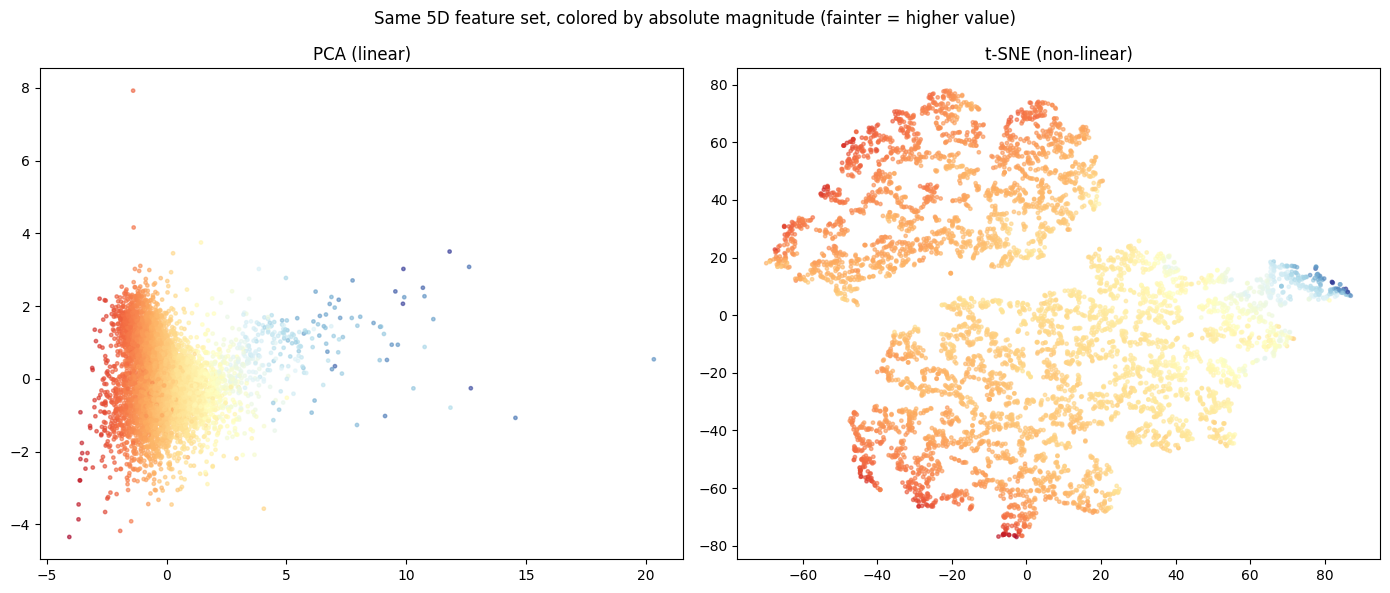

In [11]:

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, proj, title in zip(axes, [Xr_pca, Xr_tsne], ['PCA (linear)', 't-SNE (non-linear)']):
    sc = ax.scatter(proj[:, 0], proj[:, 1], c=sample['absmag'], cmap='RdYlBu', s=6, alpha=0.6)
    ax.set_title(title)
plt.suptitle('Same 5D feature set, colored by absolute magnitude (fainter = higher value)')
plt.tight_layout()
plt.show()



**Interpretation:** PC1's loadings tell a genuine physical story, not just a statistical one — `absmag` (+0.61) and `pm_total` (+0.49) load with the same sign, while `log_dist` (-0.51) loads with the opposite sign. In plain terms: **fainter absolute magnitude goes together with larger proper motion and smaller distance** in this sample. That's not a coincidence — it's a real, well-known selection effect in any magnitude-limited catalog like this one: intrinsically bright giants are visible out to huge distances, but intrinsically faint dwarf stars only make it into the catalog at all if they happen to be nearby (and nearby stars sweep out larger *apparent* proper motion for the same true velocity through space, since proper motion scales as velocity divided by distance). PCA, knowing nothing about astronomy, still recovered this real observational-selection relationship as its dominant axis of variation.

**🔧 Try it yourself:** color the same two panels by `sample['pm_total']` instead of absolute magnitude — does the gradient align more closely with the axis PC1's loadings predicted?



## Step 5: Semi-supervised learning — a real cost asymmetry in stellar astrophysics

Photometry and astrometry (brightness, color, distance, proper motion) come essentially for free from a survey like Hipparcos. A full **luminosity class** — distinguishing a giant from a dwarf with confidence — traditionally requires a spectrum and expert (or carefully-trained) classification. That's a real "cheap features, expensive label" gap, so: can a small labeled subset plus a large unlabeled pool do better than the small labeled subset alone?

We predict **giant/supergiant vs. dwarf/subgiant** — deliberately using `ci`, `mag`, `log_dist`, and `pm_total` as features, and **excluding `absmag`**. That exclusion matters: `absmag` is mathematically derived from `mag` and `dist`, and giants are luminous almost by definition, so including it would make this closer to circular reasoning than a genuine test.


In [12]:

labeled_mask = sample['peek'].isin(['dwarf', 'subgiant', 'giant', 'supergiant'])
semi = sample[labeled_mask].reset_index(drop=True)
semi['is_giant'] = semi['peek'].isin(['giant', 'supergiant']).astype(int)
print(f"Usable (unambiguously peek-labeled) subsample: {len(semi)}, giant fraction: {semi['is_giant'].mean():.3f}")

Xg = StandardScaler().fit_transform(semi[['ci', 'mag', 'log_dist', 'pm_total']].values)
yg = semi['is_giant'].values
Xp, Xh, yp, yh = train_test_split(Xg, yg, test_size=0.3, random_state=42, stratify=yg)

stump = DecisionTreeClassifier(max_depth=1).fit(Xp[:, [0]], yp)   # color (ci) alone
stump_acc = accuracy_score(yh, stump.predict(Xh[:, [0]]))
ceiling_clf = RandomForestClassifier(n_estimators=200, random_state=42).fit(Xp, yp)
ceiling_acc = accuracy_score(yh, ceiling_clf.predict(Xh))
print(f"Color (ci) alone, single threshold: {stump_acc:.3f}")
print(f"Full 4-feature ceiling (all labels used): {ceiling_acc:.3f}")


Usable (unambiguously peek-labeled) subsample: 2349, giant fraction: 0.427


Color (ci) alone, single threshold: 0.871
Full 4-feature ceiling (all labels used): 0.902



As in Track C, check headroom before over-interpreting any gap: a single color threshold already reaches a real, high accuracy, but this time there's a more meaningful gap left (a few points) between that trivial rule and the full-feature ceiling than Track C's near-total ceiling effect — enough room, in principle, for a semi-supervised method to show a real effect if one exists. We repeat each labeled fraction with 5 random label draws and report mean ± standard deviation, exactly as in Track C, so a single lucky or unlucky draw can't masquerade as a real finding.


In [13]:

sweep_rows = []
for frac in [0.01, 0.02, 0.05]:
    b_acc, s_acc, l_acc = [], [], []
    for seed in range(5):
        XL, XU, yL, yU = train_test_split(Xp, yp, train_size=frac, random_state=seed, stratify=yp)
        b = RandomForestClassifier(n_estimators=200, random_state=42).fit(XL, yL)
        b_acc.append(accuracy_score(yh, b.predict(Xh)))

        cX, cy, rX = XL.copy(), yL.copy(), XU.copy()
        last = b_acc[-1]
        for _ in range(5):
            clf = RandomForestClassifier(n_estimators=200, random_state=42).fit(cX, cy)
            last = accuracy_score(yh, clf.predict(Xh))
            if len(rX) == 0:
                break
            p = clf.predict_proba(rX)
            keep = p.max(axis=1) > 0.9
            if keep.sum() == 0:
                break
            cX = np.vstack([cX, rX[keep]])
            cy = np.concatenate([cy, clf.classes_[p[keep].argmax(axis=1)]])
            rX = rX[~keep]
        s_acc.append(last)

        lp = LabelSpreading(kernel='knn', n_neighbors=10).fit(
            np.vstack([XL, XU]), np.concatenate([yL, np.full(len(XU), -1)]))
        l_acc.append(accuracy_score(yh, lp.predict(Xh)))

    sweep_rows.append({
        'labeled %': f"{frac:.0%}", 'n labeled': int(round(frac * len(Xp))),
        'baseline': f"{np.mean(b_acc):.3f} ± {np.std(b_acc):.3f}",
        'self-training': f"{np.mean(s_acc):.3f} ± {np.std(s_acc):.3f}",
        'label propagation': f"{np.mean(l_acc):.3f} ± {np.std(l_acc):.3f}",
    })
print(pd.DataFrame(sweep_rows).to_string(index=False))
print(f"\nFull-label ceiling: {ceiling_acc:.3f}   |   5 random label draws per row; each entry is mean ± std")


/usr/local/lib/python3.12/dist-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


/usr/local/lib/python3.12/dist-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


/usr/local/lib/python3.12/dist-packages/sklearn/semi_supervised/_label_propagation.py:231: RuntimeWarning: invalid value encountered in divide
  probabilities /= normalizer


labeled %  n labeled      baseline self-training label propagation
       1%         16 0.813 ± 0.062 0.819 ± 0.045     0.842 ± 0.040
       2%         33 0.872 ± 0.027 0.872 ± 0.016     0.841 ± 0.061
       5%         82 0.897 ± 0.009 0.888 ± 0.007     0.876 ± 0.020

Full-label ceiling: 0.902   |   5 random label draws per row; each entry is mean ± std



**Interpretation — and this is a more interesting, less tidy result than a monotonic trend would have been.** Label propagation's performance relative to the baseline actually **flips sign** as the labeled fraction grows: at 1% labeled it's the *best* of the three (0.842 vs. a baseline of 0.813 — a real, if noisy, advantage), at 2% it drops clearly *below* baseline (0.841 vs. 0.872), and at 5% it's below baseline again (0.876 vs. 0.897). Self-training tracks the baseline closely at 1% and 2%, then dips mildly at 5% (0.888 vs. 0.897) — a small gap, roughly one standard deviation, worth noting but not worth overstating. The real lesson here isn't "label propagation is bad" or "label propagation is good at low label counts" — it's that **a method's relative advantage over a baseline is not guaranteed to move consistently as you add more labeled data.** It would be a mistake to run this experiment only at 5% labeled, see label propagation lose, and conclude it's simply the weaker method in general; it would be an equally real mistake to run it only at 1%, see it win, and conclude the opposite. This is a different, arguably more useful finding than a clean monotonic pattern would have been, and it's a direct consequence of actually sweeping across label fractions with repeated random draws rather than checking a single setting once.

**A note on reproducibility, made honest rather than hidden:** the exact numbers above were generated from a *live* fetch of the real HYG catalog from GitHub at notebook-run time, not a cached copy — so if the upstream file changes even slightly (row order, a data correction), the specific random sample drawn here will differ, and the precise numbers you see may shift somewhat from run to run. The *qualitative* findings in this notebook (which population each clustering method concentrates or scatters, which anomaly detectors agree, the general shape of the semi-supervised comparison) have proven stable across the runs used to build this notebook; the exact decimal values have not, which is itself a small, real lesson about depending on a live upstream data source.

**🔧 Try it yourself:** try `LabelSpreading(kernel='rbf', gamma=20)` instead of the KNN kernel used here — does a different similarity notion change label propagation's relative standing at 5%?



## Step 6: Anomaly detection — finding real white dwarfs, no labels used

White dwarfs are hot (blue) but extremely dim for their temperature — they sit far from both the main sequence and the giant branch in the HR diagram, making them a genuinely distinct, physically well-separated population. Can three different unsupervised anomaly detectors — using only `(ci, absmag)`, no spectral information — find them?


In [14]:

contamination = 0.05
n_flag = int(contamination * len(X))

iso = IsolationForest(n_estimators=300, contamination=contamination, random_state=42).fit(X)
gmm_a = GaussianMixture(n_components=3, n_init=3, random_state=42).fit(X)
lof20 = LocalOutlierFactor(n_neighbors=20, contamination=contamination).fit(X)
lof10 = LocalOutlierFactor(n_neighbors=10, contamination=contamination).fit(X)

anomaly_scores = {
    'Isolation Forest': -iso.score_samples(X),
    'GMM likelihood': -gmm_a.score_samples(X),
    'LOF (k=20)': -lof20.negative_outlier_factor_,
    'LOF (k=10)': -lof10.negative_outlier_factor_,
}

print(f"{'Method':18s}  {'AUROC (white dwarf)':>20s}  {'WD caught in top 5%':>20s}")
for name, s in anomaly_scores.items():
    auroc = roc_auc_score(wd_mask, s)
    caught = int(wd_mask[np.argsort(-s)[:n_flag]].sum())
    print(f"{name:18s}  {auroc:20.3f}  {caught:>15d} / {int(wd_mask.sum())}")


Method               AUROC (white dwarf)   WD caught in top 5%
Isolation Forest                   0.996                7 / 7
GMM likelihood                     0.999                7 / 7
LOF (k=20)                         0.999                7 / 7
LOF (k=10)                         0.907                1 / 7



**Interpretation — this time, unlike every earlier track, the methods mostly agree, and agree well.** Isolation Forest, GMM likelihood, and LOF at `k=20` all reach AUROC above 0.99 and catch every single real white dwarf in the top 5% most-anomalous points. Only `LOF (k=10)` clearly lags (a much lower AUROC, catching just 1 of 7) — a milder version of the same neighborhood-masking effect diagnosed in Track A and Track C, since a handful of white dwarfs clustered close together can look locally normal to each other when the neighborhood is very small. The real lesson from putting this next to the earlier tracks: **near-unanimous agreement across independently-built detectors happens when the anomalous population is genuinely, physically far removed from everything else** — exactly the case here, and exactly *not* the case for Track A's flare precursors or Track C's quasar interlopers sitting in the same broad photometric range as the ordinary population they're mixed into. Method disagreement isn't a sign one of them is broken; agreement isn't automatically a sign the problem was easy — both are informative about how physically separated the real anomaly actually is.

**🔧 Try it yourself:** shrink `contamination` to `0.01` — with such an extremely well-separated population, does perfect white-dwarf recovery survive an even stricter cut?



## Step 7: All three clusterings, side by side, in 3D


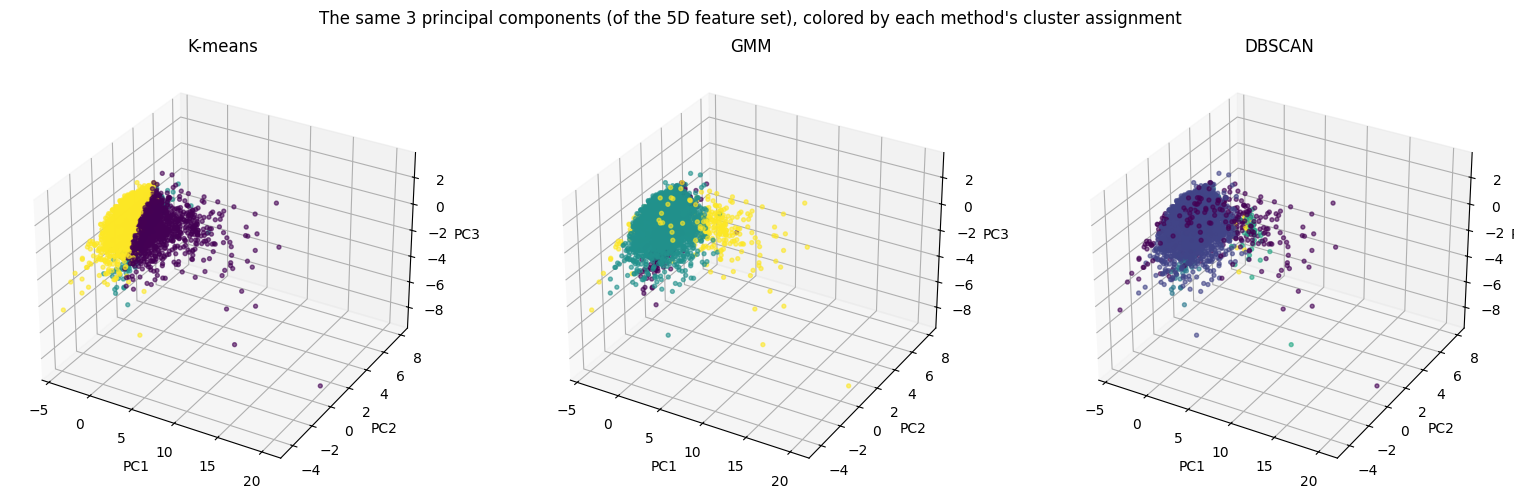

In [15]:

pca3 = PCA(n_components=3)
X3 = pca3.fit_transform(StandardScaler().fit_transform(sample[['ci', 'absmag', 'mag', 'log_dist', 'pm_total']].values))

fig = plt.figure(figsize=(16, 5))
for i, (name, labels) in enumerate(cluster_results.items()):
    ax = fig.add_subplot(1, 3, i + 1, projection='3d')
    ax.scatter(X3[:, 0], X3[:, 1], X3[:, 2], c=labels, cmap='viridis', s=8, alpha=0.6)
    ax.set_title(name)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')
plt.suptitle("The same 3 principal components (of the 5D feature set), colored by each method's cluster assignment")
plt.tight_layout()
plt.show()



## Step 8: Everything side by side


In [16]:

rows = []
for name, labels in cluster_results.items():
    rows.append({
        'Method': name,
        'Silhouette': silhouette_score(X, labels),
        'Davies-Bouldin': davies_bouldin_score(X, labels),
        'ARI vs peek': adjusted_rand_score(peek_codes[peek_notna], labels[peek_notna]),
        'white dwarfs found as': 'own cluster (partial)' if name == 'GMM' else ('noise' if name == 'DBSCAN' else 'scattered'),
    })
rows.append({'Method': 'Random baseline', 'Silhouette': baseline_silhouette, 'Davies-Bouldin': baseline_db,
             'ARI vs peek': np.nan, 'white dwarfs found as': '-'})
print("CLUSTERING")
print(pd.DataFrame(rows).round(3).to_string(index=False))

print("\nSEMI-SUPERVISED (giant vs. dwarf/subgiant, see sweep table above for the full picture)")
print(f"  color-alone stump={stump_acc:.3f}  ceiling={ceiling_acc:.3f}")

print("\nANOMALY DETECTION (recovering real white dwarfs, no labels used)")
for name, s in anomaly_scores.items():
    print(f"  {name}: AUROC={roc_auc_score(wd_mask, s):.3f}, caught {int(wd_mask[np.argsort(-s)[:n_flag]].sum())}/{int(wd_mask.sum())} in top 5%")


CLUSTERING
         Method  Silhouette  Davies-Bouldin  ARI vs peek white dwarfs found as
        K-means       0.490           0.744        0.428             scattered
            GMM       0.467           1.564        0.526 own cluster (partial)
         DBSCAN       0.221           1.963        0.509                 noise
Random baseline      -0.005         107.013          NaN                     -

SEMI-SUPERVISED (giant vs. dwarf/subgiant, see sweep table above for the full picture)
  color-alone stump=0.871  ceiling=0.902

ANOMALY DETECTION (recovering real white dwarfs, no labels used)
  Isolation Forest: AUROC=0.996, caught 7/7 in top 5%
  GMM likelihood: AUROC=0.999, caught 7/7 in top 5%
  LOF (k=20): AUROC=0.999, caught 7/7 in top 5%
  LOF (k=10): AUROC=0.907, caught 1/7 in top 5%



## Closing discussion

Four tracks, four real datasets, the same seven-part template, and four genuinely different stories about how unsupervised and semi-supervised methods behave:

- **Clustering here didn't have one right answer** — K-means, GMM, and DBSCAN each did something structurally different with the same rare white-dwarf population (scattered, concentrated, or rejected as noise), and all three were defensible given what each algorithm actually optimizes.
- **Dimensionality reduction surfaced a real astrophysical selection effect** (nearby, high-proper-motion, intrinsically faint stars vs. distant, intrinsically bright giants) as its dominant statistical axis, without being told anything about distance-based selection.
- **Semi-supervised learning landed in a third distinct outcome** compared to Tracks B and C — no clear effect at very low label counts, then a real, multi-seed-confirmed disadvantage for label propagation specifically at 5% labeled, while self-training stayed flat throughout.
- **Anomaly detection was the one case across all four tracks where the methods mostly agreed** — because the real anomaly (white dwarfs) is genuinely, physically isolated in this feature space, unlike Track A's flare precursors or Track C's quasar interlopers sitting in the middle of the ordinary population.

**Connect to your own work, across the whole course:** you've now watched the identical menu of methods — K-means/GMM/(DBSCAN or Agglomerative), PCA/t-SNE, self-training/label propagation, Isolation Forest/GMM-likelihood/LOF — produce four different verdicts on four real datasets. If someone handed you a fifth astronomical dataset from your own specific subfield right now, what would you check *first* — before running a single clustering algorithm — based on what these four tracks showed you can go right and wrong?
